**PCA y Regresión Logística**









In [3]:
# Librerías a utilizar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset
from sklearn.datasets import fetch_openml

**Referencia**

https://www.openml.org/d/554


The MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples.  

*   Tipo de parámetros = Número
*   Clases =	10
*   Ejemplos por clase =~ 7000 
*   Ejemplos en total = 70000
*   Dimensiones =	784
*   Características =	valores enteros desde 0 a 255

In [7]:
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [4]:
mnist = fetch_openml('mnist_784')
print("Dimensión de los datos = ",mnist.data.shape)
print("Dimensión de las etiquetas = ",mnist.target.shape)

Dimensión de los datos =  (70000, 784)
Dimensión de las etiquetas =  (70000,)


**Visualización de datos**

In [12]:
X_imag_entrenamiento = mnist.data
Y_imag_entrenamiento = mnist.target
# print(X_imag_entrenamiento.vales[100, :])

In [21]:
print(type(X_imag_entrenamiento.values))

<class 'numpy.ndarray'>


El valor de la etiqueta es:  0 



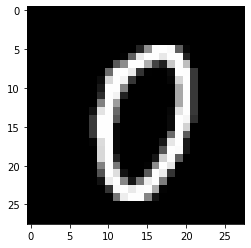

In [14]:
selector = 1000;  # 0 a 70000
X_preview = X_imag_entrenamiento.values
imag = X_preview[selector, :]
imag = np.reshape(imag, (28,28) )
plt.imshow(imag, cmap='gray')
print("El valor de la etiqueta es: ", Y_imag_entrenamiento[selector], "\n")

**Preparación para el PCA**

In [40]:
# Importancia del escalado de datos
# https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html

# Es conveniente ajustar la escala de los datos
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# Ajustar sobre las imágenes de entrenamiento.
scaler.fit(X_escalado)

# Aplicar las transformaciones sobre X e Y
X_escalado = scaler.transform(X_imag_entrenamiento)

# Verificación
print(X_escalado.shape)

/usr/local/lib/python3.7/dist-packages/sklearn/base.py:444: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  f"X has feature names, but {self.__class__.__name__} was fitted without"


(70000, 784)


**Descomposición PCA**

In [41]:
from sklearn.decomposition import PCA

# Creamos una instancia de PCA con el 95% de la varianza explicada
pca = PCA(400)

In [42]:
pca

PCA(n_components=400)

In [43]:
# Ajustamos el PCA con nuestro conjunto de entrenamiento
pca.fit(X_imag_entrenamiento)

PCA(n_components=400)

In [44]:
# Cantidad de componentes dimensionalmente reducidos  
pca.n_components_

400

In [45]:
# Aplicamos la transformacion sobre nuestro conjunto de datos
X_menor_dimension = pca.transform(X_escalado)
print("Pasamos de tener ", X_escalado.shape[1], "--->", X_menor_dimension.shape[1] )

/usr/local/lib/python3.7/dist-packages/sklearn/base.py:451: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  "X does not have valid feature names, but"


Pasamos de tener  784 ---> 400


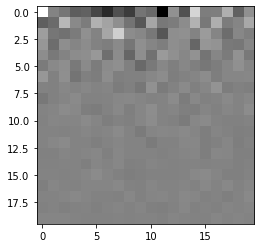

In [46]:
selector = 500;  # 0 a 70000
X_preview = X_menor_dimension
imag = X_preview[selector, :]
imag = np.reshape(imag, (20,20) )
plt.imshow(imag, cmap='gray')

**Como elegimos el número de componentes?**

*Grafico de varianza explicada vs el número de componentes principales* 

In [ ]:
# Creamos una instancia PCA
pca = PCA()
pca.fit(X_escalado)

PCA(copy=True, iterated_power='auto', n_components=None, random_state=None,
    svd_solver='auto', tol=0.0, whiten=False)

In [ ]:
pca.n_components_

784

In [ ]:
# La cantidad de varianza explicada por cada uno de los componentes seleccionados 
pca.explained_variance_

array([4.05717285e+01, 2.90568291e+01, 2.68785692e+01, 2.08009648e+01,
       1.81244641e+01, 1.57646528e+01, 1.37638842e+01, 1.25156954e+01,
       1.10169049e+01, 1.00380057e+01, 9.65037627e+00, 8.63834298e+00,
       8.00950033e+00, 7.84139416e+00, 7.39132242e+00, 7.15382734e+00,
       6.69582232e+00, 6.61226831e+00, 6.38912392e+00, 6.20646328e+00,
       5.90840528e+00, 5.74069722e+00, 5.48297738e+00, 5.33732321e+00,
       5.15221035e+00, 4.95623838e+00, 4.89932919e+00, 4.70655246e+00,
       4.51030375e+00, 4.38844572e+00, 4.29436653e+00, 4.23715539e+00,
       4.07936583e+00, 4.02183857e+00, 3.97233838e+00, 3.84270332e+00,
       3.79345098e+00, 3.70895102e+00, 3.63458298e+00, 3.43282671e+00,
       3.42473228e+00, 3.34451105e+00, 3.26038307e+00, 3.20503935e+00,
       3.18027237e+00, 3.14838269e+00, 3.14418625e+00, 3.07537728e+00,
       3.05441235e+00, 3.00923043e+00, 2.90522929e+00, 2.84913789e+00,
       2.82697237e+00, 2.80817775e+00, 2.77856944e+00, 2.71427006e+00,
      

In [ ]:
# Calculamos el porcentaje de la varianza explicada por cada componente
tot = sum(pca.explained_variance_)
var_exp = [(i/tot)*100 for i in sorted(pca.explained_variance_, reverse=True)] 

In [ ]:
# Acumulación de la varianza explicada
cum_var_exp = np.cumsum(var_exp)

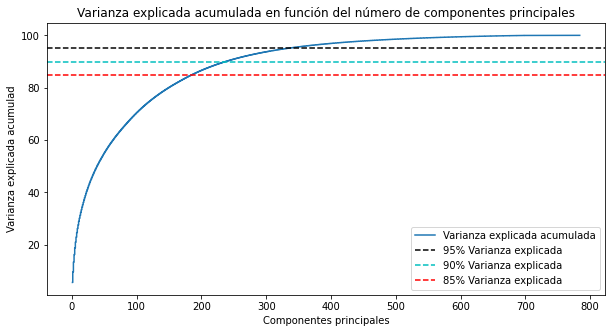

In [ ]:
# Con este gráfico entenderemos las redundancias presentes en múltiples dimensiones

plt.figure(figsize=(10, 5))
plt.step(range(1, 785), cum_var_exp, where='mid',label='Varianza explicada acumulada')
plt.title('Varianza explicada acumulada en función del número de componentes principales')
plt.ylabel('Varianza explicada acumulad')
plt.xlabel('Componentes principales')
plt.axhline(y = 95, color='k', linestyle='--', label = '95% Varianza explicada')
plt.axhline(y = 90, color='c', linestyle='--', label = '90% Varianza explicada')
plt.axhline(y = 85, color='r', linestyle='--', label = '85% Varianza explicada')
plt.legend(loc='best')
plt.show()

**Regresión Logística**

In [ ]:
# Importamos librerías para la regresión logistica
from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical

# Aplicamos un modelo para 10 regresiones logisticas ya que tenemos 10 clases diferentes
model = Sequential()
model.add(Dense(10, activation = 'sigmoid', input_shape=( X_menor_dimension.shape[1], )))

model.compile(optimizer = 'adam',
             loss = 'categorical_crossentropy',
             metrics = ['accuracy'])

In [ ]:
# Cambiar a variables categóricas
Y_etiquetas_entrenamiento = to_categorical(Y_imag_entrenamiento)
print(Y_etiquetas_entrenamiento.shape)
print(Y_imag_entrenamiento[16701,])  
print(Y_etiquetas_entrenamiento[16701, :])      

(70000, 10)
2
[0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
# Entrenamos el modelo
model.fit(X_menor_dimension, Y_etiquetas_entrenamiento, epochs = 50, batch_size = 128)

Epoch 1/50
547/547 [==============================] - 1s 1ms/step - loss: 1.6476 - accuracy: 0.5599
Epoch 2/50
547/547 [==============================] - 1s 1ms/step - loss: 0.3873 - accuracy: 0.8982
Epoch 3/50
547/547 [==============================] - 1s 1ms/step - loss: 0.3160 - accuracy: 0.9139
Epoch 4/50
547/547 [==============================] - 1s 1ms/step - loss: 0.2903 - accuracy: 0.9194
Epoch 5/50
547/547 [==============================] - 1s 1ms/step - loss: 0.2817 - accuracy: 0.9213
Epoch 6/50
547/547 [==============================] - 1s 1ms/step - loss: 0.2759 - accuracy: 0.9221
Epoch 7/50
547/547 [==============================] - 1s 1ms/step - loss: 0.2685 - accuracy: 0.9254
Epoch 8/50
547/547 [==============================] - 1s 1ms/step - loss: 0.2617 - accuracy: 0.9262
Epoch 9/50
547/547 [==============================] - 1s 1ms/step - loss: 0.2629 - accuracy: 0.9268
Epoch 10/50
547/547 [==============================] - 1s 1ms/step - loss: 0.2602 - accuracy: 0.9274

In [ ]:
# Evaluamos el modelo con métricas
from sklearn import metrics

loss, acc = model.evaluate(X_menor_dimension, Y_etiquetas_entrenamiento)
print("Precisión: ",acc,"\n Valores de pérdida:",loss)

2188/2188 [==============================] - 2s 822us/step - loss: 0.2416 - accuracy: 0.9332
Precisión:  0.9331714510917664 
 Valores de pérdida: 0.2416338175535202


**Comparación**

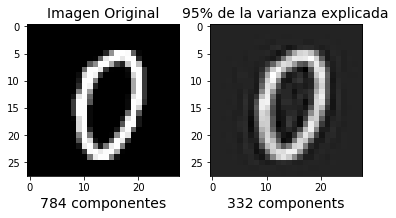

In [ ]:
selector = 1000;

imag = X_preview[selector, :]
imag = np.reshape(imag, (28,28) )
imag_aprox_PCA = X_menor_dimension[selector, :]
imag_aprox_PCA = pca.inverse_transform(imag_aprox_PCA)
imag_aprox_PCA = scaler.inverse_transform(imag_aprox_PCA)

plt.subplot(1, 2, 1);
plt.imshow(imag, cmap='gray')
plt.xlabel('784 componentes', fontsize = 14)
plt.title('Imagen Original', fontsize = 14);
# print("El valor de la etiqueta es: ", Y_imag_entrenamiento[selector])

plt.subplot(1, 2, 2);
imag_aprox_PCA = np.reshape(imag_aprox_PCA, (28,28) )
plt.imshow(imag_aprox_PCA, cmap='gray')
plt.xlabel('332 components', fontsize = 14)
plt.title('95% de la varianza explicada', fontsize = 14);
# print("El valor de la etiqueta es: ", Y_imag_entrenamiento[selector])

**Referencias**

*  https://github.com/mGalarnyk/Python_Tutorials/blob/master/Sklearn/PCA/PCA_to_Speed-up_Machine_Learning_Algorithms.ipynb
*  https://github.com/mGalarnyk/Python_Tutorials/blob/master/Sklearn/PCA/PCA_Image_Reconstruction_and_such.ipynb
*  https://towardsdatascience.com/pca-using-python-scikit-learn-e653f8989e60
*  https://www.kaggle.com/pmmilewski/pca-decomposition-and-keras-neural-network

